# 15 · Harris Corners and Non-Maximum Suppression

LRT4012 Robot Vision · Fall 2026


## Local variation in two directions

$$M=\sum_{(u,v)\in W} w(u,v)\begin{bmatrix}I_x^2&I_xI_y\\I_xI_y&I_y^2\end{bmatrix},\qquad R=\det(M)-k\,[\operatorname{tr}(M)]^2.$$

$W$ is a neighborhood around the evaluated pixel, $(u,v)$ indexes its samples, $w$ is a nonnegative weight, and $I_x,I_y$ are image derivatives. $M$ is the second-moment matrix, $k$ is the Harris sensitivity factor, and $R$ is the corner response. Two large eigenvalues indicate variation in two directions. Thresholding selects positive responses; non-maximum suppression (NMS) retains local peaks. Detection and description are separate operations.


## Experimental protocol and files

Official images are read from `imagenes`. Personal notebooks belong in `student_work`; captured or generated images belong in `student_work/imagenes`. No cell writes to the official resource directory. Relative discovery supports a cloned course repository; `VISION_ROBOTICA_REPO` is an optional local override.

Predict the effect of each parameter before running a comparison. Keep image size and acquisition conditions fixed. Timing reports the median of 30 runs after one warm-up, excludes plotting and file access, and describes this computer only. Random generators use seed 4012. A missing detection is an experimental result, not evidence that no object exists.


In [1]:
from pathlib import Path
import os, time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_repository():
    candidates = []
    if os.environ.get('VISION_ROBOTICA_REPO'):
        candidates.append(Path(os.environ['VISION_ROBOTICA_REPO']).expanduser())
    candidates += [Path.cwd(), *Path.cwd().parents]
    for root in candidates:
        if (root / 'requirements.txt').is_file() and (root / 'imagenes').is_dir():
            return root.resolve()
    raise FileNotFoundError('Open Jupyter inside the course repository, or set VISION_ROBOTICA_REPO to its root.')

REPO = find_repository()
IMAGE_DIR = REPO / 'imagenes'  # Read-only official resources.
# Save your own notebook and generated images in student_work/ and student_work/imagenes/.
cv2.setRNGSeed(4012)
cv2.setNumThreads(1)
rng = np.random.default_rng(4012)
plt.rcParams.update({'figure.dpi':100, 'font.size':10})

def load_image(name, max_side=640):
    image = cv2.imread(str(IMAGE_DIR / name), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f'Official resource could not be read: {name}')
    h, w = image.shape[:2]
    if max(h, w) > max_side:
        scale = max_side / max(h, w)
        image = cv2.resize(image, (round(w*scale), round(h*scale)), interpolation=cv2.INTER_AREA)
    return image

def gray(image): return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

def panels(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(4*len(images), 3.5), squeeze=False)
    for ax, im, title in zip(axes[0], images, titles):
        if im.ndim == 3:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(im, cmap='gray', vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis('off')
    fig.tight_layout()
    plt.show()

def timed_ms(fn, repetitions=30):
    fn()  # Warm-up.
    times = []
    for _ in range(repetitions):
        start = time.perf_counter()
        fn()
        times.append((time.perf_counter()-start)*1000)
    return float(np.median(times))

def mask_metrics(prediction, reference):
    a, b = prediction.astype(bool), reference.astype(bool)
    tp = int(np.count_nonzero(a & b))
    fp = int(np.count_nonzero(a & ~b))
    fn = int(np.count_nonzero(~a & b))
    return {'IoU': tp/(tp+fp+fn) if tp+fp+fn else 1.0,
            'precision': tp/(tp+fp) if tp+fp else np.nan,
            'recall': tp/(tp+fn) if tp+fn else np.nan,
            'F1': 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 1.0}


In [2]:
def harris_points(g, quality=0.02, min_distance=8):
    response = cv2.cornerHarris(np.float32(g),2,3,0.04)
    maximum = float(response.max())
    if maximum <= 0: return [], response
    peaks = (response == cv2.dilate(response,np.ones((3,3),np.uint8))) & (response>quality*maximum)
    ys,xs=np.where(peaks)
    order=np.argsort(response[ys,xs])[::-1]
    selected=[]
    for i in order:
        p=np.array([xs[i],ys[i]],float)
        if all(np.linalg.norm(p-q)>=min_distance for q in selected): selected.append(p)
        if len(selected)>=500: break
    return [cv2.KeyPoint(float(p[0]),float(p[1]),7) for p in selected],response

def detect(g, method):
    if method=='Harris': return harris_points(g)[0]
    if method=='Shi-Tomasi':
        points=cv2.goodFeaturesToTrack(g,500,0.02,8)
        return [] if points is None else [cv2.KeyPoint(float(x),float(y),7) for x,y in points.reshape(-1,2)]
    if method=='FAST': return cv2.FastFeatureDetector_create(threshold=25,nonmaxSuppression=True).detect(g,None)
    detector=cv2.ORB_create(nfeatures=500) if method=='ORB' else cv2.SIFT_create(nfeatures=500)
    return detector.detect(g,None)

def overlay(image, points):
    return cv2.drawKeypoints(image,points,None,color=(0,180,255),flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)


,relative_threshold,corners
0,0.01,207
1,0.03,162
2,0.08,109


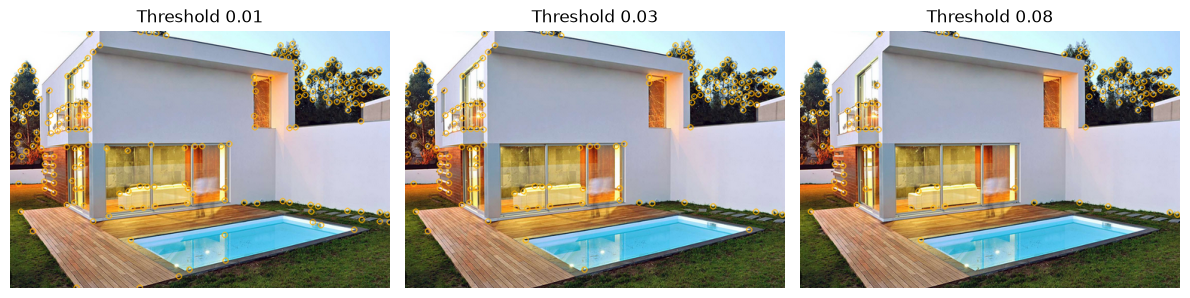

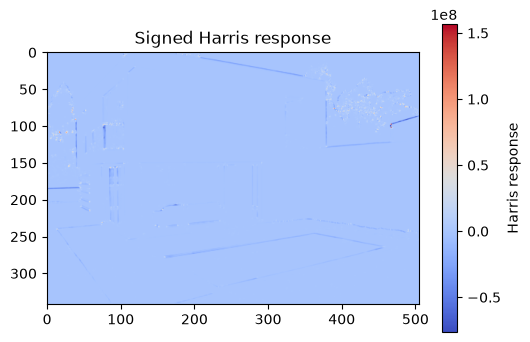

In [3]:
image=load_image('casa.png'); g=gray(image)
rows=[]; views=[]
for quality in [0.01,0.03,0.08]:
    points,response=harris_points(g,quality)
    rows.append({'relative_threshold':quality,'corners':len(points)})
    views.append(overlay(image,points))
display(pd.DataFrame(rows))
panels(views,['Threshold 0.01','Threshold 0.03','Threshold 0.08'])
fig,ax=plt.subplots(figsize=(6,4)); im=ax.imshow(response,cmap='coolwarm'); fig.colorbar(im,ax=ax,label='Harris response'); ax.set_title('Signed Harris response'); plt.show()


## Robotic interpretation

Identify corners on different surfaces. Explain why many adjacent points on one textured patch give poor spatial coverage for robot localization. Distinguish NMS from the minimum-distance rule.


## References

- [OpenCV: Harris](https://docs.opencv.org/4.x/dc/d0d/tutorial_py_features_harris.html)
- [OpenCV: ORB parameters](https://docs.opencv.org/4.13.0/db/d95/classcv_1_1ORB.html)
- [OpenCV: SIFT](https://docs.opencv.org/4.x/da/df5/tutorial_py_sift_intro.html)
